# EODH Community Notebook Competition 2026

## _Multi-Scale Satellite Flood Early-Warning and Parametric Risk Trigger across Kenya and Nigeria_

### Description of Notebook
_A multi-scale hydrological workflow that synergises 26 years of daily EOCIS Soil Moisture ($0.25^\circ$) with Copernicus $10\text{ m}$ Land Cover (CLMS) and Sentinel-2 $10\text{ m}$ multispectral imagery via `pyeodh` to resolve coarse-pixel basis risk and validate flood early-warning triggers against 62 historical disasters._

* Author(s): Flawiya S. More
* Organisation / affiliation: University of Liverpool (MSc Geographic Data Science) / Environmental Data Scientist
* Language: Python
* Date: 2026-11-17


## 1. Purpose

Flood early-warning systems and parametric disaster insurance across Sub-Saharan Africa face a fundamental **spatial scale dilemma**: macro-hydrological satellite models ($0.25^\circ \approx 28\text{ km}$) capture daily catchment soil saturation (the regional "sponge"), but average out narrow floodplains, croplands, and human settlements across a massive $\sim 770\text{ km}^2$ grid cell. Treating a $28\text{ km}$ pixel as uniform causes severe **basis risk**, where uninhabited bushland ($>65\%$ of a cell) dilutes the hazard signal over critical towns ($0.2\%$) and farmland ($1\%$).

**What the reader should learn:** This notebook demonstrates how to connect daily continental climate data (`eocis-soil-moisture-africa`) with high-resolution static exposure (`clms-lcm-global-10m-yearly-v1-cog`) and on-demand $10\text{ m}$ optical flood mapping (`sentinel-2-c1-l2a`) using the EO Data Hub (`pyeodh`) STAC API. Readers will learn how to compute standardized day-of-year soil-moisture anomalies ($Z$-scores), deconstruct coarse pixels using $10\text{ m}$ Cloud-Optimized GeoTIFFs (COGs) without downloading full tiles, and benchmark early-warning triggers against historical disasters.

### Objectives

1. **Construct a 26-Year Hydrological Baseline (2000–2026):** Derive daily day-of-year rolling standardized anomalies ($Z$-scores) of root-zone soil moisture and 7-day rainfall across Kenya and Nigeria from the EODH EOCIS catalogue.
2. **Resolve Sub-Pixel Basis Risk at $10\text{ m}$:** Stream Copernicus $10\text{ m}$ Land Cover (CLMS) COGs via EODH to quantify the exact sub-pixel fraction of urban settlements and croplands inside a $0.25^\circ$ macro-cell.
3. **Verify Sub-Pixel Inundation with $10\text{ m}$ Sentinel-2 MNDWI:** Stream pre-flood and peak-flood Sentinel-2 L2A bands from EODH during the May 2024 Kenya flood emergency to map the physical floodplain footprint inside the triggered macro-cell.
4. **Benchmark Empirical Skill & Formulate a Decision Matrix:** Evaluate trigger skill across 62 documented flood events from the Dartmouth Flood Observatory (DFO), explaining the physical divergence between rainfall-driven catchment floods (Kenya) and transboundary fluvial floods (Nigeria).

### Expected outputs

* **Climatology & Data Quality Maps:** 25-year mean annual rainfall, root-zone soil moisture ($0\text{--}1\text{ m}$), and seasonal hydrological regimes for Nigeria and Kenya.
* **Sub-Pixel Exposure Breakdown:** High-resolution ($10\text{ m}$) land cover map and asset vulnerability table within a $0.25^\circ$ ($\sim 770\text{ km}^2$) catchment cell (Tana River / Garissa, Kenya).
* **Multi-Scale Flood Verification Figure:** Coupled time-series and $10\text{ m}$ Sentinel-2 Modified Normalized Difference Water Index (MNDWI) flood footprint for the May 2024 Kenya disaster.
* **Empirical Validation & Decision Matrix:** Skill percentiles across 62 historical floods and an operational 3-tier parametric alert matrix.


## 2. Background and approach

### Workflow overview

1. **Catalogue Discovery via `pyeodh`:** Connect to `https://eodatahub.org.uk` using `pyeodh.Client` and inspect three open STAC collections across the CEDA and Element84 catalogues (`eocis-soil-moisture-africa`, `clms-lcm-global-10m-yearly-v1-cog`, and `sentinel-2-c1-l2a`).
2. **Macro-Scale Anomaly Engine ($0.25^\circ$):** Load the 26-year (2000–2026, 9,528 days) daily soil moisture and precipitation series for Kenya and Nigeria. Sum the top three JULES soil layers ($0\text{--}10$, $10\text{--}35$, and $35\text{--}100\text{ cm}$) to obtain top-$1\text{ m}$ water storage ($\text{kg}\cdot\text{m}^{-2} = \text{mm}$) and compute day-of-year rolling $Z$-scores ($\pm 7$-day window):
   $$Z_{\text{SM}}(t) = \frac{\text{SM}(t) - \mu_{\text{DOY}}}{\sigma_{\text{DOY}}}$$
3. **Sub-Pixel Exposure Profiling ($10\text{ m}$ CLMS COG):** Perform a windowed HTTP read (`rasterio.windows.from_bounds`) on the EODH CLMS $10\text{ m}$ GeoTIFF covering the Garissa / Tana River $0.25^\circ$ grid cell ($[39.50^\circ\text{E}, -0.55^\circ\text{N}, 39.75^\circ\text{E}, -0.30^\circ\text{N}]$) to separate high-exposure assets (built-up settlements and cropland) from uninhabited shrubland.
4. **Physical Inundation Verification ($10\text{ m}$ Sentinel-2 MNDWI):** Query EODH for cloud-free dry-season baseline (`2024-03-10`) and flood-peak (`2024-05-19`) Sentinel-2 L2A scenes over Garissa, stream the Green ($\text{B03}$, $10\text{ m}$) and SWIR16 ($\text{B11}$, $20\text{ m}$) bands, and compute the Modified Normalized Difference Water Index (Xu, 2006):
   $$\text{MNDWI} = \frac{\text{Green} - \text{SWIR16}}{\text{Green} + \text{SWIR16}}$$
5. **Historical Disaster Benchmarking:** Compare event-window trigger maxima ($[t_{\text{start}}-7\text{d}, t_{\text{end}}+7\text{d}]$) against the same calendar season in all other baseline years across 62 documented DFO flood events.

* **Reproducibility:** This notebook runs end-to-end in **under 60 seconds** on standard CPU instances (no GPU or authentication tokens required). To avoid re-downloading 9,528 daily NetCDF files (which takes ~40 minutes via `src/02_download_soil_moisture.py`), the repository includes lightweight pre-aggregated summary files (`data/summary/`, $<3\text{ MB}$ total) while performing **live windowed streaming** from EODH for the EOCIS, CLMS $10\text{ m}$, and Sentinel-2 $10\text{ m}$ rasters.


## 3. Data and other inputs

| Dataset / input | Provider | Access location | Licence / terms | Date accessed | Purpose |
|---|---|---|---|---|---|
| **EOCIS Soil Moisture Africa v2.3.1** | TAMSAT / Univ. of Reading / NCEO via CEDA | EODH STAC: `public/catalogs/ceda-stac-catalogue` / `eocis-soil-moisture-africa` | Open Access (CEDA / UK EOCIS terms) | 2026-11-17 | 26-year daily soil moisture ($0\text{--}1\text{ m}$) & rainfall baseline ($0.25^\circ$) |
| **CLMS Global Land Cover 10 m (2020 v1)** | Copernicus Land Monitoring Service via CEDA | EODH STAC: `public/catalogs/ceda-stac-catalogue` / `clms-lcm-global-10m-yearly-v1-cog` | Open Access (Copernicus free & open data policy) | 2026-11-17 | Sub-pixel ($10\text{ m}$) urban & agricultural asset exposure profiling |
| **Sentinel-2 Collection 1 Level-2A** | ESA / Copernicus via Element84 | EODH STAC: `public/catalogs/element84` / `sentinel-2-c1-l2a` | Open Access (Copernicus Sentinel data notice) | 2026-11-17 | $10\text{ m}$ multispectral MNDWI flood extent mapping |
| **geoBoundaries (ADM0 / ADM1)** | William & Mary geoLab | `https://www.geoboundaries.org/` (`data/summary/*_ADM*.geojson`) | CC BY 4.0 / Public Domain | 2026-11-17 | National and state/county vector masks |
| **DFO Flood Archive (2000–2024)** | Dartmouth Flood Observatory / HDX | `https://data.humdata.org/` (`docs/dfo_events_nigeria_kenya.csv`) | CC BY 4.0 | 2026-11-17 | Ground-truth flood event validation (62 events) |

### Area and period of interest

**Area:**
* **Macro-scale study domains:** Kenya ($[33.7^\circ\text{E}, -5.1^\circ\text{N}, 42.2^\circ\text{E}, 5.7^\circ\text{N}]$) and Nigeria ($[2.5^\circ\text{E}, 3.9^\circ\text{N}, 15.0^\circ\text{E}, 14.2^\circ\text{N}]$).
* **Micro-scale focal cell ($0.25^\circ \times 0.25^\circ$):** Tana River floodplain at Garissa, Kenya ($[39.50^\circ\text{E}, -0.55^\circ\text{N}, 39.75^\circ\text{E}, -0.30^\circ\text{N}]$).

**Period:**
* **Climatological baseline:** `2000-01-01` to `2026-01-31` (9,528 continuous days).
* **High-resolution Sentinel-2 flood verification:** `2024-03-10` (dry baseline) vs. `2024-05-19` (Kenya Long Rains flood peak).


## 4. Environment and setup

This notebook runs in Python on the standard **EODH JupyterLab** environment. All required packages are pre-installed on EODH; if running locally, install from `requirements.txt`.

### Dependencies

```python
pyeodh==0.1.12
numpy>=2.0
pandas>=2.0
xarray>=2024.1
netCDF4>=1.6
geopandas>=1.1.0
shapely>=2.1.0
rasterio>=1.3
pyproj>=3.6
matplotlib>=3.8
pystac-client>=0.8
```

_NOTE:_ No API keys, credentials, or tokens are required because all datasets used in this workflow are openly accessible via the EODH public STAC catalogues.


In [1]:
# Install missing packages if running in a fresh environment (uncomment if needed)
# %pip install --quiet pyeodh==0.1.12 xarray netCDF4 geopandas rasterio shapely pyproj matplotlib pandas pystac-client

import os
import warnings
warnings.filterwarnings("ignore")

import pyeodh
import shapely
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import ListedColormap

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

# Explicit configuration for reproducibility
BASE_URL = "https://eodatahub.org.uk"
CEDA_CATALOG = "public/catalogs/ceda-stac-catalogue"
E84_CATALOG = "public/catalogs/element84"

# Focal 0.25-deg macro-cell: Garissa / Tana River floodplain, Kenya
AOI_GARISSA_BBOX = (39.50, -0.55, 39.75, -0.30)  # (lon_min, lat_min, lon_max, lat_max)
AOI_GARISSA_POINT = shapely.Point(39.64, -0.45)
BASELINE_START = "2000-01-01"
BASELINE_END = "2026-01-31"
S2_DRY_DATE = "2024-03-10"
S2_FLOOD_DATE = "2024-05-19"

print(f"pyeodh version: {pyeodh.__version__} | Configuration loaded successfully.")


pyeodh version: 0.1.12 | Configuration loaded successfully.


In [2]:
# Connect to the EO Data Hub Catalogue Service using pyeodh
client = pyeodh.Client(base_url=BASE_URL).get_catalog_service()

ceda_cat = client.get_catalog(CEDA_CATALOG)
e84_cat = client.get_catalog(E84_CATALOG)

eocis_sm = ceda_cat.get_collection("eocis-soil-moisture-africa")
clms_lc = ceda_cat.get_collection("clms-lcm-global-10m-yearly-v1-cog")
s2_l2a = e84_cat.get_collection("sentinel-2-c1-l2a")

for coll in [eocis_sm, clms_lc, s2_l2a]:
    print(f"Collection ID : {coll.id}")
    print(f"Title         : {coll.title}")
    print("-" * 75)


Collection ID : eocis-soil-moisture-africa
Title         : EOCIS Soil Moisture Africa v2.3.1
---------------------------------------------------------------------------
Collection ID : clms-lcm-global-10m-yearly-v1-cog
Title         : Copernicus Land Monitoring Service (CLMS) Land Cover Map (LCM) global 10m 2020
---------------------------------------------------------------------------
Collection ID : sentinel-2-c1-l2a
Title         : Sentinel-2 Collection 1 Level-2A
---------------------------------------------------------------------------


## 5. Results and visualisation

### 5.1 Macro-Hydrological Climatology & Seasonal Regimes ($0.25^\circ$ EOCIS)
We first examine the 26-year (2000–2026) spatial climatology and seasonal water-balance regimes across Nigeria and Kenya derived from `eocis-soil-moisture-africa`.
* **Physical Interpretation:** Nigeria exhibits a single-peak West African Monsoon regime (rainfall peaking in August, top-$1\text{ m}$ soil moisture peaking in September), whereas Kenya exhibits an equatorial bimodal regime with distinct **Long Rains (March–May)** and **Short Rains (October–December)**. Because soil moisture integrates antecedent rainfall minus evapotranspiration and drainage, it acts as a low-pass filter that measures catchment storage capacity.


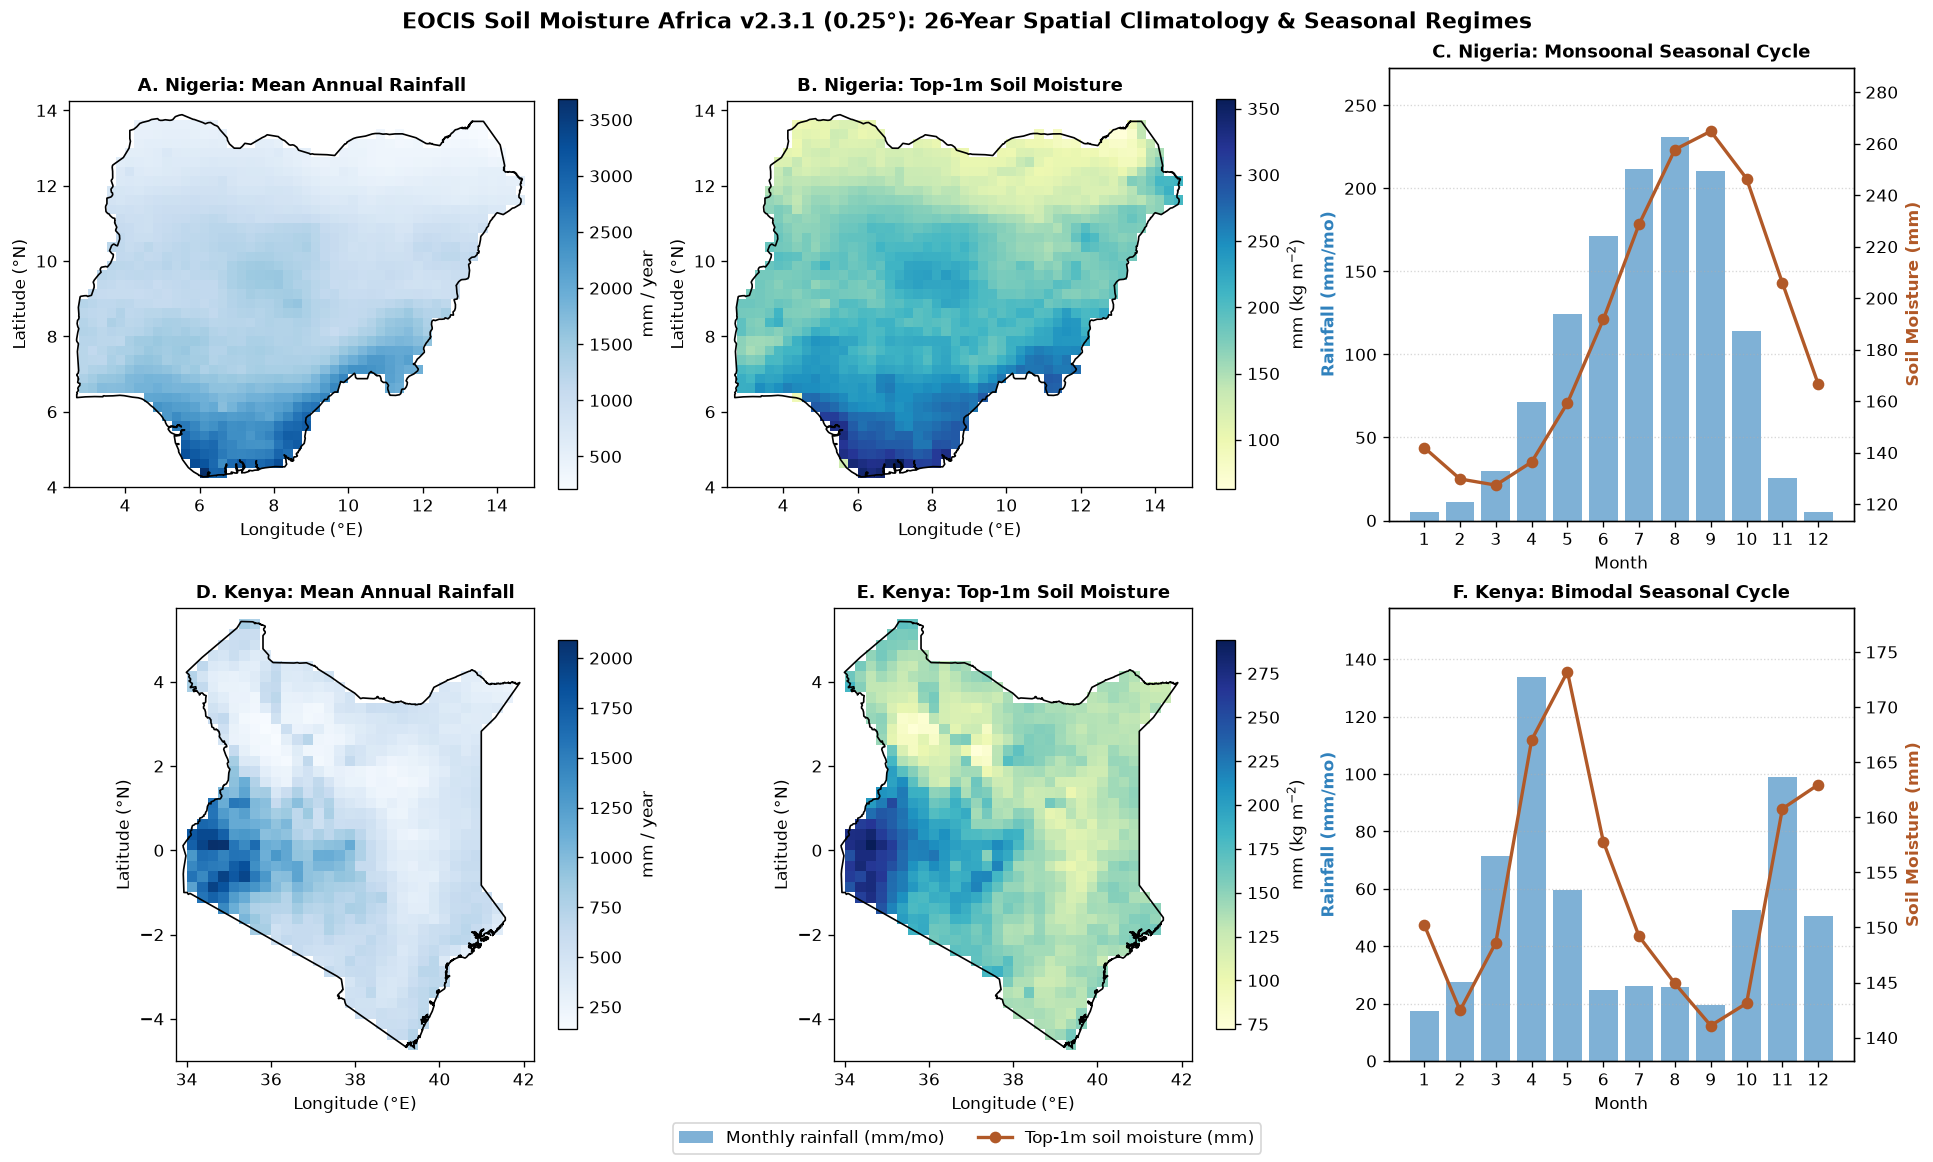

In [3]:
# Load compact 26-year climatology grids and daily time series
clim_ken = xr.open_dataset("data/summary/kenya_climatology_grid.nc")
clim_nga = xr.open_dataset("data/summary/nigeria_climatology_grid.nc")
adm0_ken = gpd.read_file("data/summary/KEN_ADM0.geojson")
adm0_nga = gpd.read_file("data/summary/NGA_ADM0.geojson")
df_ts = pd.read_csv("data/summary/daily_timeseries_2000_2026.csv", parse_dates=["time"])

fig, axs = plt.subplots(2, 3, figsize=(16, 9.6), layout="constrained")

# Row 1: Nigeria (Rainfall map, Soil moisture map, Seasonal cycle)
clim_nga["mean_annual_rain_mm"].where(clim_nga["mean_annual_rain_mm"] > 0).plot(
    ax=axs[0, 0], cmap="Blues", cbar_kwargs={"label": "mm / year", "shrink": 0.86}
)
adm0_nga.boundary.plot(ax=axs[0, 0], color="k", lw=1)
axs[0, 0].set_title("A. Nigeria: Mean Annual Rainfall", fontweight="bold", fontsize=11, pad=6)
axs[0, 0].set_xlabel("Longitude (°E)"); axs[0, 0].set_ylabel("Latitude (°N)")

clim_nga["mean_sm_top1m_mm"].plot(
    ax=axs[0, 1], cmap="YlGnBu", cbar_kwargs={"label": "mm (kg m$^{-2}$)", "shrink": 0.86}
)
adm0_nga.boundary.plot(ax=axs[0, 1], color="k", lw=1)
axs[0, 1].set_title("B. Nigeria: Top-1m Soil Moisture", fontweight="bold", fontsize=11, pad=6)
axs[0, 1].set_xlabel("Longitude (°E)"); axs[0, 1].set_ylabel("Latitude (°N)")

ts_nga = df_ts[df_ts.region == "nigeria"].set_index("time")
mon_nga_rain = ts_nga["rain_mm"].groupby(ts_nga.index.month).mean() * 30.4
mon_nga_sm = ts_nga["sm_top1m"].groupby(ts_nga.index.month).mean()
axs[0, 2].bar(mon_nga_rain.index, mon_nga_rain.values, color="#3182bd", alpha=0.62, label="Monthly rainfall (mm/mo)")
axs[0, 2].set_ylim(0, float(mon_nga_rain.max()) * 1.18)
ax0_r = axs[0, 2].twinx()
ax0_r.plot(mon_nga_sm.index, mon_nga_sm.values, "o-", color="#b15928", lw=2, label="Top-1m soil moisture (mm)")
s_span0 = float(mon_nga_sm.max() - mon_nga_sm.min())
ax0_r.set_ylim(float(mon_nga_sm.min()) - 0.1 * s_span0, float(mon_nga_sm.max()) + 0.18 * s_span0)
axs[0, 2].set_title("C. Nigeria: Monsoonal Seasonal Cycle", fontweight="bold", fontsize=11, pad=6)
axs[0, 2].set_xlabel("Month"); axs[0, 2].set_ylabel("Rainfall (mm/mo)", color="#3182bd", fontweight="bold")
ax0_r.set_ylabel("Soil Moisture (mm)", color="#b15928", fontweight="bold")
axs[0, 2].set_xticks(range(1, 13)); axs[0, 2].grid(axis="y", ls=":", alpha=0.5)

# Row 2: Kenya (Rainfall map, Soil moisture map, Seasonal cycle)
clim_ken["mean_annual_rain_mm"].where(clim_ken["mean_annual_rain_mm"] > 0).plot(
    ax=axs[1, 0], cmap="Blues", cbar_kwargs={"label": "mm / year", "shrink": 0.86}
)
adm0_ken.boundary.plot(ax=axs[1, 0], color="k", lw=1)
axs[1, 0].set_title("D. Kenya: Mean Annual Rainfall", fontweight="bold", fontsize=11, pad=6)
axs[1, 0].set_xlabel("Longitude (°E)"); axs[1, 0].set_ylabel("Latitude (°N)")

clim_ken["mean_sm_top1m_mm"].plot(
    ax=axs[1, 1], cmap="YlGnBu", cbar_kwargs={"label": "mm (kg m$^{-2}$)", "shrink": 0.86}
)
adm0_ken.boundary.plot(ax=axs[1, 1], color="k", lw=1)
axs[1, 1].set_title("E. Kenya: Top-1m Soil Moisture", fontweight="bold", fontsize=11, pad=6)
axs[1, 1].set_xlabel("Longitude (°E)"); axs[1, 1].set_ylabel("Latitude (°N)")

ts_ken = df_ts[df_ts.region == "kenya"].set_index("time")
mon_ken_rain = ts_ken["rain_mm"].groupby(ts_ken.index.month).mean() * 30.4
mon_ken_sm = ts_ken["sm_top1m"].groupby(ts_ken.index.month).mean()
axs[1, 2].bar(mon_ken_rain.index, mon_ken_rain.values, color="#3182bd", alpha=0.62, label="Monthly rainfall (mm/mo)")
axs[1, 2].set_ylim(0, float(mon_ken_rain.max()) * 1.18)
ax1_r = axs[1, 2].twinx()
ax1_r.plot(mon_ken_sm.index, mon_ken_sm.values, "o-", color="#b15928", lw=2, label="Top-1m soil moisture (mm)")
s_span1 = float(mon_ken_sm.max() - mon_ken_sm.min())
ax1_r.set_ylim(float(mon_ken_sm.min()) - 0.1 * s_span1, float(mon_ken_sm.max()) + 0.18 * s_span1)
axs[1, 2].set_title("F. Kenya: Bimodal Seasonal Cycle", fontweight="bold", fontsize=11, pad=6)
axs[1, 2].set_xlabel("Month"); axs[1, 2].set_ylabel("Rainfall (mm/mo)", color="#3182bd", fontweight="bold")
ax1_r.set_ylabel("Soil Moisture (mm)", color="#b15928", fontweight="bold")
axs[1, 2].set_xticks(range(1, 13)); axs[1, 2].grid(axis="y", ls=":", alpha=0.5)

h_b, l_b = axs[0, 2].get_legend_handles_labels()
h_l, l_l = ax0_r.get_legend_handles_labels()
fig.legend(h_b + h_l, l_b + l_l, loc="outside lower center", ncol=2, frameon=True, fontsize=10)
fig.suptitle("EOCIS Soil Moisture Africa v2.3.1 (0.25°): 26-Year Spatial Climatology & Seasonal Regimes", fontsize=13, fontweight="bold")
plt.show()


### 5.2 Resolving the $28\text{ km}$ Scale Dilemma: Sub-Pixel Exposure Profiling ($10\text{ m}$ CLMS)
Why is a single $0.25^\circ$ pixel value insufficient on its own for localized flood risk? At the equator, $0.25^\circ \times 0.25^\circ$ spans **$28\text{ km} \times 28\text{ km} \approx 770\text{ km}^2$** (roughly half the size of Greater London).

Below, we use `pyeodh` to query the **Copernicus Land Monitoring Service (CLMS) $10\text{ m}$ Land Cover** collection (`clms-lcm-global-10m-yearly-v1-cog`) for the Garissa / Tana River cell and stream the $3000 \times 3000$ sub-pixel window ($9,000,000$ pixels at $10\text{ m}$) directly over HTTP.


Found CLMS 10m Tile via pyeodh: LCFM_LCM-10_V100_2020_S03E039_MAP
Streaming COG Window from     : https://dap.ceda.ac.uk/neodc/copernicus_land_cover/data/2020/v1/LCFM_LCM-10_V100_2020_S03E039_MAP.tif


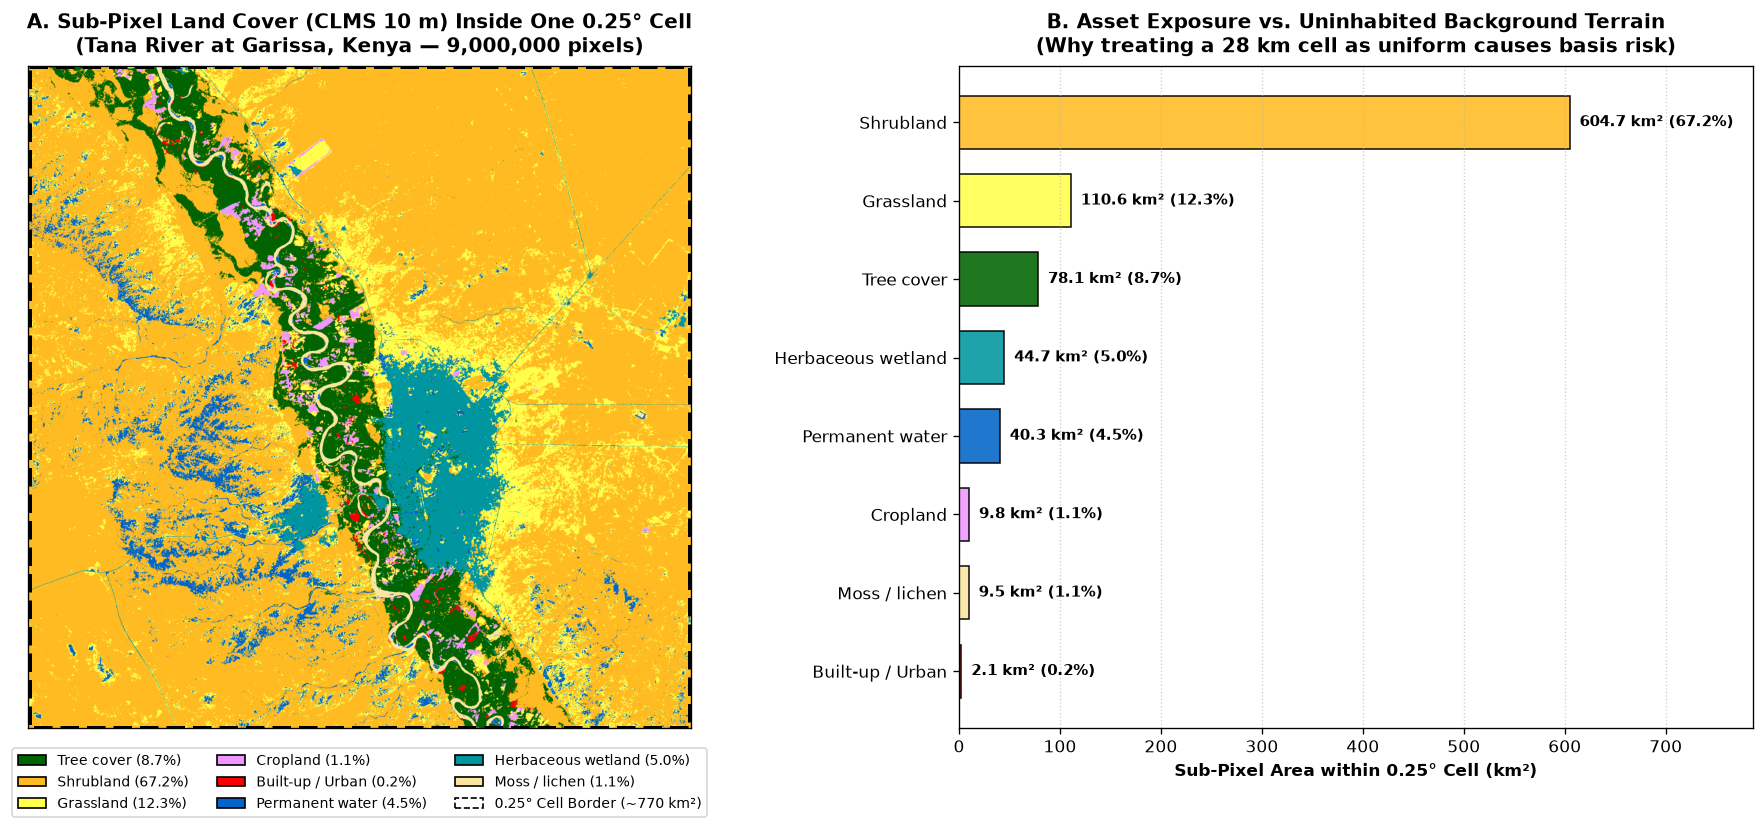

,code,label,area_km2,share_pct,vuln_weight
1,20,Shrubland,604.74,67.19,0.00
2,30,Grassland,110.65,12.29,0.05
0,10,Tree cover,78.12,8.68,0.00
6,90,Herbaceous wetland,44.68,4.96,0.30
5,80,Permanent water,40.32,4.48,0.00
3,40,Cropland,9.81,1.09,0.70
7,100,Moss / lichen,9.54,1.06,0.00
4,50,Built-up / Urban,2.15,0.24,1.00


In [4]:
# Query EODH for the CLMS 10m Land Cover tile intersecting Garissa
clms_items = list(
    client.search(
        collections=["clms-lcm-global-10m-yearly-v1-cog"],
        catalog_paths=[CEDA_CATALOG],
        intersects=AOI_GARISSA_POINT,
    )
)
clms_item = clms_items[0]
clms_href = clms_item.assets["data"].href
print(f"Found CLMS 10m Tile via pyeodh: {clms_item.id}")
print(f"Streaming COG Window from     : {clms_href}")

with rasterio.open(clms_href) as src:
    win = from_bounds(*AOI_GARISSA_BBOX, src.transform)
    lc = src.read(1, window=win)

CLASS_MAP = {
    10: ("Tree cover", "#006400", 0.0),
    20: ("Shrubland", "#ffbb22", 0.0),
    30: ("Grassland", "#ffff4c", 0.05),
    40: ("Cropland", "#f096ff", 0.70),
    50: ("Built-up / Urban", "#fa0000", 1.00),
    80: ("Permanent water", "#0064c8", 0.0),
    90: ("Herbaceous wetland", "#0096a0", 0.30),
    100: ("Moss / lichen", "#fae6a0", 0.0),
}

total_px = lc.size
stats = []
for code, (label, color, vuln_weight) in CLASS_MAP.items():
    cnt = int(np.sum(lc == code))
    if cnt > 0:
        stats.append({
            "code": code, "label": label, "color": color, "vuln_weight": vuln_weight,
            "area_km2": (cnt * 100) / 1e6, "share_pct": (cnt / total_px) * 100
        })
df_stats = pd.DataFrame(stats).sort_values("area_km2", ascending=False)

unique_codes = [s["code"] for s in stats]
code_to_idx = {c: i for i, c in enumerate(unique_codes)}
indexed_lc = np.zeros_like(lc, dtype=int)
for c in unique_codes:
    indexed_lc[lc == c] = code_to_idx[c]

fig, axs = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1.1, 1.1]}, layout="constrained")
axs[0].imshow(indexed_lc, cmap=ListedColormap([s["color"] for s in stats]))
h, w = lc.shape
axs[0].add_patch(Rectangle((2, 2), w - 4, h - 4, lw=3, edgecolor="black", facecolor="none", ls="--"))
axs[0].set_title("A. Sub-Pixel Land Cover (CLMS 10 m) Inside One 0.25° Cell\n(Tana River at Garissa, Kenya — 9,000,000 pixels)", fontweight="bold", pad=8)
axs[0].set_xticks([]); axs[0].set_yticks([])

legend_els = [Patch(facecolor=s["color"], edgecolor="k", label=f"{s['label']} ({s['share_pct']:.1f}%)") for s in stats]
legend_els.append(Patch(facecolor="none", edgecolor="black", ls="--", label="0.25° Cell Border (~770 km²)"))
axs[0].legend(handles=legend_els, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8.5, frameon=True)

bars = axs[1].barh(df_stats["label"], df_stats["area_km2"], color=df_stats["color"], edgecolor="k", alpha=0.88, height=0.68)
axs[1].invert_yaxis()
axs[1].set_xlabel("Sub-Pixel Area within 0.25° Cell (km²)", fontweight="bold")
axs[1].set_title("B. Asset Exposure vs. Uninhabited Background Terrain\n(Why treating a 28 km cell as uniform causes basis risk)", fontweight="bold", pad=8)
for bar in bars:
    width = bar.get_width()
    pct = (width / df_stats["area_km2"].sum()) * 100
    axs[1].text(width + 10, bar.get_y() + bar.get_height() / 2, f"{width:.1f} km² ({pct:.1f}%)", va="center", fontsize=8.8, fontweight="bold")
axs[1].set_xlim(0, max(df_stats["area_km2"]) * 1.30)
axs[1].grid(axis="x", ls=":", alpha=0.6)

plt.show()

display(df_stats[["code", "label", "area_km2", "share_pct", "vuln_weight"]].round(2))


### 5.3 Multi-Scale Inundation Verification ($10\text{ m}$ Sentinel-2 MNDWI vs. $0.25^\circ$ EOCIS)
During the **April–May 2024 Kenya Long Rains**, severe flooding along the Tana River displaced hundreds of thousands of residents. Here we verify whether the coarse $0.25^\circ$ EOCIS soil-moisture anomaly ($Z_{\text{SM}} > +1.5$) provided early warning of actual surface inundation at $10\text{ m}$ resolution.

Using `pyeodh`, we query `sentinel-2-c1-l2a` over Garissa for:
* **Dry-season baseline (`2024-03-10`):** Confined permanent river channel prior to the heavy rains.
* **Peak flood inundation (`2024-05-19`):** Cloud-free scene ($1.5\%$ cloud cover) during peak flood wave propagation.


Dry Baseline Scene : S2A_T37MEV_20240310T074424_L2A (Cloud cover: 16.6%)
Peak Flood Scene   : S2A_T37MEV_20240519T074617_L2A (Cloud cover: 1.5%)


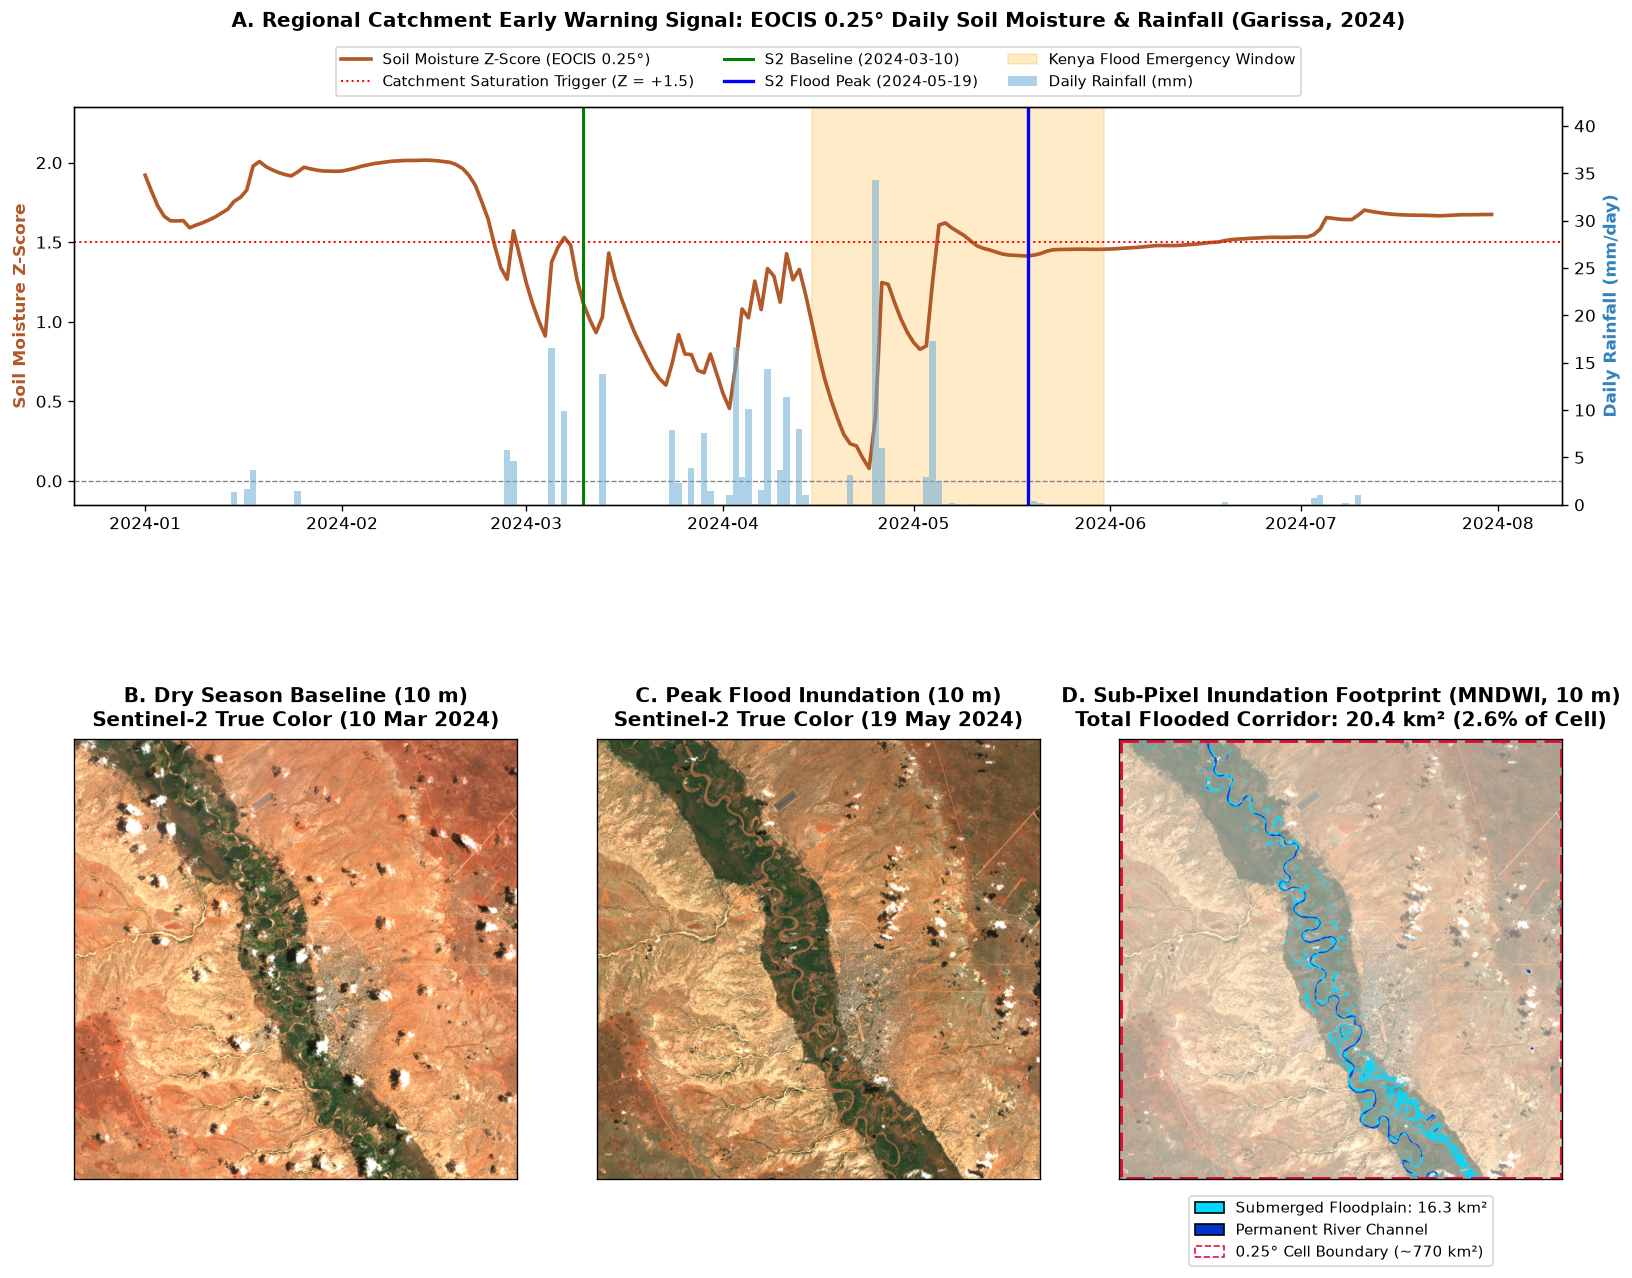

In [5]:
# Retrieve Sentinel-2 L2A scenes via pyeodh for the Garissa focal cell in March-May 2024
it_dry = s2_l2a.get_item("S2A_T37MEV_20240310T074424_L2A")
it_flood = s2_l2a.get_item("S2A_T37MEV_20240519T074617_L2A")
print(f"Dry Baseline Scene : {it_dry.id} (Cloud cover: {it_dry.properties.get('eo:cloud_cover'):.1f}%)")
print(f"Peak Flood Scene   : {it_flood.id} (Cloud cover: {it_flood.properties.get('eo:cloud_cover'):.1f}%)")

def stream_s2_mndwi(item, bounds_4326):
    # Stream windowed RGB (10m), Green (B03, 10m), and SWIR16 (B11, 20m) from EODH Sentinel-2 COG
    with rasterio.open(item.assets["visual"].href) as src_vis:
        b_utm = transform_bounds("EPSG:4326", src_vis.crs, *bounds_4326)
        win = from_bounds(*b_utm, src_vis.transform)
        rgb = np.clip(src_vis.read(window=win).transpose(1, 2, 0) / 255.0, 0, 1)
    with rasterio.open(item.assets["green"].href) as src_g:
        green = src_g.read(1, window=win).astype(float)
    with rasterio.open(item.assets["swir16"].href) as src_swir:
        win_swir = from_bounds(*b_utm, src_swir.transform)
        swir = src_swir.read(1, window=win_swir, out_shape=green.shape).astype(float)
    denom = green + swir
    mndwi = np.where(denom > 0, (green - swir) / denom, -1.0)
    return rgb, mndwi

rgb_dry, mndwi_dry = stream_s2_mndwi(it_dry, AOI_GARISSA_BBOX)
rgb_flood, mndwi_flood = stream_s2_mndwi(it_flood, AOI_GARISSA_BBOX)

water_dry = mndwi_dry > 0.0
water_flood = mndwi_flood > -0.05
new_inundation = water_flood & (~water_dry)

inundation_km2 = (int(np.sum(new_inundation)) * 100) / 1e6
total_water_km2 = (int(np.sum(water_flood)) * 100) / 1e6
cell_area_km2 = (water_flood.size * 100) / 1e6

# Plot 4-panel multi-scale figure
df_gar = df_ts[(df_ts.region == "garissa_cell") & (df_ts.time >= "2024-01-01") & (df_ts.time <= "2024-07-31")].set_index("time")

fig = plt.figure(figsize=(16, 12.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.05, 1.45], hspace=0.38, wspace=0.18)

ax_ts = fig.add_subplot(gs[0, :])
ax_rain = ax_ts.twinx()
ax_rain.bar(df_gar.index, df_gar["rain_mm"], width=1.0, color="#6baed6", alpha=0.55, label="Daily Rainfall (mm)")
ax_ts.plot(df_gar.index, df_gar["sm_z"], color="#b15928", lw=2.2, label="Soil Moisture Z-Score (EOCIS 0.25°)")
ax_ts.axhline(0, color="gray", lw=0.8, ls="--")
ax_ts.axhline(1.5, color="red", lw=1.2, ls=":", label="Catchment Saturation Trigger (Z = +1.5)")
ax_ts.axvline(pd.Timestamp(S2_DRY_DATE), color="green", lw=1.8, label=f"S2 Baseline ({S2_DRY_DATE})")
ax_ts.axvline(pd.Timestamp(S2_FLOOD_DATE), color="blue", lw=2.0, label=f"S2 Flood Peak ({S2_FLOOD_DATE})")
ax_ts.axvspan(pd.Timestamp("2024-04-15"), pd.Timestamp("2024-05-31"), color="orange", alpha=0.22, label="Kenya Flood Emergency Window")
ax_ts.set_ylim(-0.15, 2.35)
ax_rain.set_ylim(0, 42)
ax_ts.set_ylabel("Soil Moisture Z-Score", fontweight="bold", color="#b15928")
ax_rain.set_ylabel("Daily Rainfall (mm/day)", fontweight="bold", color="#3182bd")
ax_ts.set_title("A. Regional Catchment Early Warning Signal: EOCIS 0.25° Daily Soil Moisture & Rainfall (Garissa, 2024)", fontweight="bold", pad=48)
h1, l1 = ax_ts.get_legend_handles_labels(); h2, l2 = ax_rain.get_legend_handles_labels()
ax_ts.legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, fontsize=8.8, frameon=True)

ax_b = fig.add_subplot(gs[1, 0])
ax_b.imshow(rgb_dry); ax_b.set_title("B. Dry Season Baseline (10 m)\nSentinel-2 True Color (10 Mar 2024)", fontweight="bold", pad=8)
ax_b.set_xticks([]); ax_b.set_yticks([])

ax_c = fig.add_subplot(gs[1, 1])
ax_c.imshow(rgb_flood); ax_c.set_title("C. Peak Flood Inundation (10 m)\nSentinel-2 True Color (19 May 2024)", fontweight="bold", pad=8)
ax_c.set_xticks([]); ax_c.set_yticks([])

ax_d = fig.add_subplot(gs[1, 2])
ax_d.imshow(rgb_flood, alpha=0.55)
overlay = np.zeros((*water_flood.shape, 4))
overlay[water_dry] = [0.0, 0.2, 0.8, 0.9]
overlay[new_inundation] = [0.0, 0.85, 1.0, 0.95]
ax_d.imshow(overlay)
h, w = water_flood.shape
ax_d.add_patch(Rectangle((2, 2), w - 4, h - 4, lw=3, edgecolor="crimson", facecolor="none", ls="--"))
ax_d.legend(handles=[
    Patch(facecolor=[0.0, 0.85, 1.0], edgecolor="k", label=f"Submerged Floodplain: {inundation_km2:.1f} km²"),
    Patch(facecolor=[0.0, 0.2, 0.8], edgecolor="k", label="Permanent River Channel"),
    Patch(facecolor="none", edgecolor="crimson", ls="--", label="0.25° Cell Boundary (~770 km²)")
], loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8.8, frameon=True, ncol=1)
ax_d.set_title(f"D. Sub-Pixel Inundation Footprint (MNDWI, 10 m)\nTotal Flooded Corridor: {total_water_km2:.1f} km² ({total_water_km2/cell_area_km2*100:.1f}% of Cell)", fontweight="bold", pad=8)
ax_d.set_xticks([]); ax_d.set_yticks([])

plt.show()


### 5.4 Empirical Validation Against 62 Historical Disasters (DFO Benchmark)
To test whether antecedent saturation triggers generalize beyond a single case study, we evaluate 26 years of daily trigger values against **62 documented historical flood disasters** (34 in Kenya, 28 in Nigeria, plus recent 2020–2024 catastrophe windows) from the **Dartmouth Flood Observatory (DFO)**.

For each documented flood window $[t_{\text{start}}-7\text{d}, t_{\text{end}}+7\text{d}]$, we compute its **inter-annual percentile skill** ($0.50 = \text{random chance}$, $1.00 = \text{wettest year on record for that calendar season}$).

#### Interpretation & Limitations (Fluvial vs. Catchment Divergence)
* **High Skill in Kenya (Median Percentile $0.72\text{--}0.80$):** Over $82\%$ of major Kenyan flood disasters occur when regional soil saturation and 7-day rainfall exceed seasonal norms, with $47\text{--}59\%$ exceeding the $80\text{th}$ percentile. Kenyan floods are predominantly driven by **Dunne saturation-excess runoff** within fast-response highland and rift catchments.
* **Low Country-Mean Skill in Nigeria (Median Percentile $0.42\text{--}0.52$):** Country-wide local soil saturation shows weak skill across historical Nigerian DFO entries, even though extreme national events (such as the **2012** and **2022** floods, shown in the case-study timelines below) do register strong compound spikes ($88\text{th}\text{--}92\text{nd}$ percentiles). This reveals an essential hydrological limitation: catastrophic floods along the lower Niger and Benue rivers are **transboundary fluvial events** driven by upstream basin inflows (from Guinea, Mali, Niger, and Cameroon's Lagdo Dam releases) rather than local rainfall alone.


Empirical Trigger Validation Summary (2000–2025 Baseline):


,country,group,index,n,median_pct,share_pct_ge_0_8,share_pct_ge_0_5
0,nigeria,major events,frac_compound,10,0.44,0.10,0.50
1,nigeria,major events,sm_z_mean,10,0.56,0.10,0.60
2,nigeria,major events,rain_z7_mean,10,0.42,0.20,0.30
3,nigeria,major events,rain_30d_z_mean,10,0.50,0.20,0.50
4,nigeria,major events,runoff_14d_z_mean,10,0.40,0.10,0.40
5,nigeria,major events,local_compound,2,0.48,0.00,0.50
12,kenya,major events,frac_compound,17,0.72,0.47,0.82
13,kenya,major events,sm_z_mean,17,0.76,0.41,0.76
14,kenya,major events,rain_z7_mean,17,0.76,0.47,0.82
15,kenya,major events,rain_30d_z_mean,17,0.80,0.59,0.82


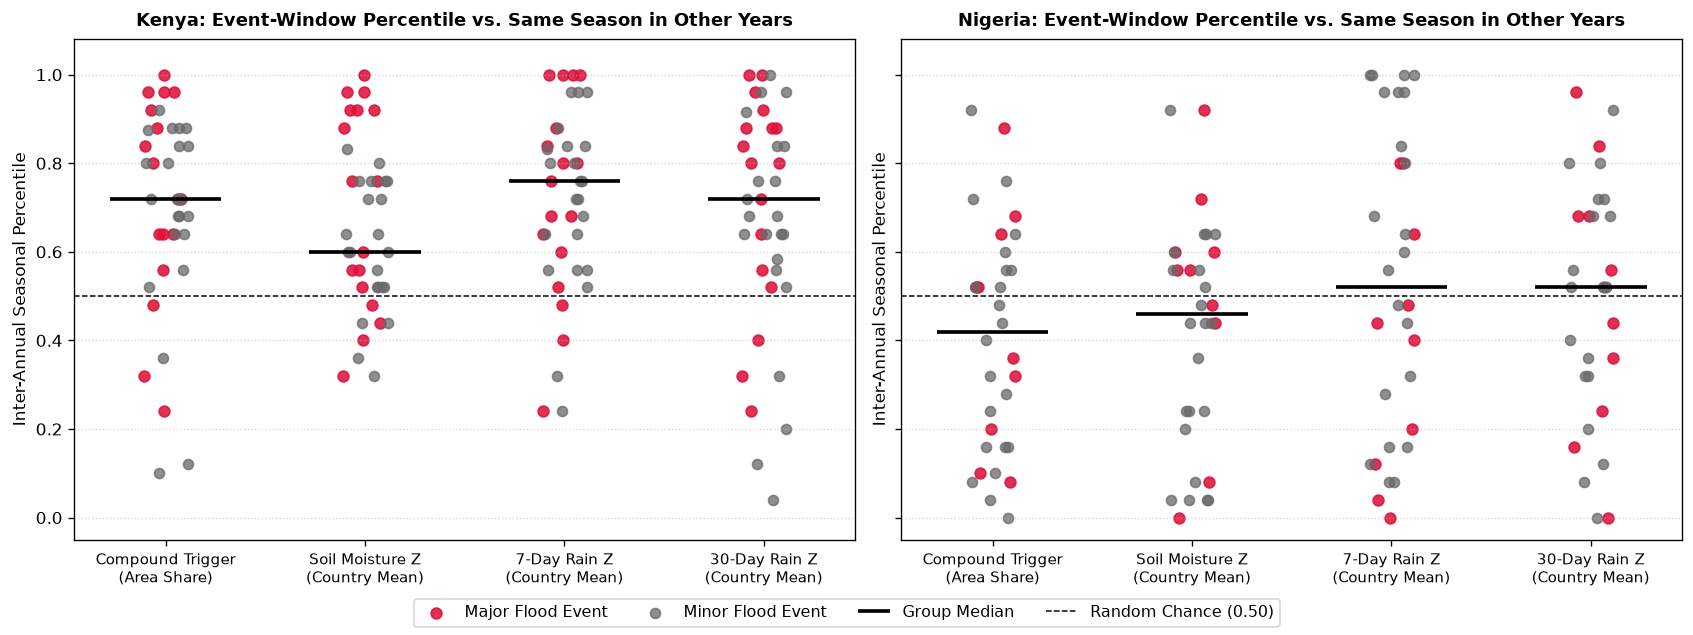

In [6]:
df_val_events = pd.read_csv("docs/trigger_validation_events.csv", parse_dates=["start", "end"])
df_val_summary = pd.read_csv("docs/trigger_validation_summary.csv")

print("Empirical Trigger Validation Summary (2000–2025 Baseline):")
display(df_val_summary[df_val_summary.group == "major events"].round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, layout="constrained")
cols = ["pct_frac_compound", "pct_sm_z_mean", "pct_rain_z7_mean", "pct_rain_30d_z_mean"]
labels = ["Compound Trigger\n(Area Share)", "Soil Moisture Z\n(Country Mean)", "7-Day Rain Z\n(Country Mean)", "30-Day Rain Z\n(Country Mean)"]

for ax, c in zip(axs, ["kenya", "nigeria"]):
    sub = df_val_events[df_val_events.country == c]
    for i, p in enumerate(cols):
        v = sub[sub[p].notnull()]
        jitter = np.random.default_rng(42).uniform(-0.12, 0.12, len(v))
        maj = v[v.major]
        minr = v[~v.major]
        ax.scatter(np.full(len(maj), i) + jitter[v.major.values], maj[p], c="crimson", s=42, alpha=0.88,
                   label="Major Flood Event" if i == 0 else None)
        ax.scatter(np.full(len(minr), i) + jitter[~v.major.values], minr[p], c="dimgray", s=36, alpha=0.75,
                   label="Minor Flood Event" if i == 0 else None)
        ax.hlines(v[p].median(), i - 0.28, i + 0.28, color="k", lw=2.2,
                  label="Group Median" if i == 0 else None)
    ax.axhline(0.5, ls="--", color="k", lw=0.9, label="Random Chance (0.50)")
    ax.set_ylim(-0.05, 1.08)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(f"{c.title()}: Event-Window Percentile vs. Same Season in Other Years", fontweight="bold", fontsize=11, pad=8)
    ax.set_ylabel("Inter-Annual Seasonal Percentile")
    ax.grid(axis="y", ls=":", alpha=0.5)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=4, frameon=True, fontsize=9.5)
plt.show()


### 5.5 Decision-Ready Parametric Flood Trigger & Early-Warning Matrix
Combining the three EODH datasets yields an operational three-stage decision protocol that minimizes basis risk for humanitarian anticipatory action (e.g., Red Cross / UN OCHA) and parametric micro-insurance (e.g., ACRE Africa):

| Alert Tier | Stage 1: Macro-Sponge Precondition (`eocis-soil-moisture-africa`, $0.25^\circ$) | Stage 2: Sub-Pixel Asset Filter (`clms-lcm-global-10m-yearly-v1-cog`, $10\text{ m}$) | Stage 3: Inundation Confirmation (`sentinel-2-c1-l2a`, $10\text{ m}$) | Decision-Ready Operational Action |
|---|---|---|---|---|
| **Tier 1: Advisory (Yellow)** | $Z_{\text{SM}} \ge +1.0$ (Catchment sponge $>84\text{th}$ pct) | Cell contains $>1\text{ km}^2$ cropland or urban settlement | Automated STAC watch initiated for next overpass | Issue early advisory to agricultural extension officers; clear urban storm drains. |
| **Tier 2: Alert (Orange)** | $Z_{\text{SM}} \ge +1.5$ AND $Z_{\text{Rain,7d}} \ge +1.0$ | Floodplain buffer intersects CLMS Class 40 (Crop) or 50 (Urban) | Windowed MNDWI confirms $\Delta\text{Water} > +5\text{ km}^2$ | Pre-position humanitarian relief stocks; issue riverine evacuation warnings. |
| **Tier 3: Payout / Crisis (Red)** | $Z_{\text{SM}} \ge +1.5$ for $\ge 5$ consecutive days | Confirmed inundation of CLMS Class 40/50 pixels | Submerged floodplain $>15\text{ km}^2$ (or SAR backup if cloudy) | **Trigger parametric insurance payout**; deploy emergency response teams. |


## 6. EO Data Hub capability demonstrated

**EODH functionality used:**
* **Unified Multi-Catalogue STAC Discovery (`pyeodh`):** Using a single `pyeodh.Client` entry point (`https://eodatahub.org.uk`), this notebook queries across both the **CEDA STAC catalogue** (`public/catalogs/ceda-stac-catalogue`) and the **Element84 Earth Search STAC catalogue** (`public/catalogs/element84`).
* **Cloud-Native Windowed Streaming (Zero-Download COG Subsetting):** Instead of downloading entire $3^\circ \times 3^\circ$ Copernicus Land Cover tiles ($>1.2\text{ GB}$ uncompressed) or full $100 \times 100\text{ km}$ Sentinel-2 granules ($>800\text{ MB}$), we pass the asset `.href` URLs returned by `pyeodh` directly into `rasterio.open()` with `from_bounds()` HTTP range requests.

**Why the Hub is useful for this workflow:**
* **Cross-Scale Data Synergy in One Platform:** Historically, researchers had to download climate reanalysis from CEDA, land cover from Copernicus portals, and optical imagery from AWS separately. EODH exposes all three through a unified STAC interface, making multi-scale ($28\text{ km} \rightarrow 10\text{ m}$) hazard-to-impact workflows fast, lightweight, and fully reproducible inside the EODH Jupyter environment.


## (Optional) References and acknowledgements

1. **Brocca, L., Melone, F., Moramarco, T., & Morbidelli, R. (2010).** Improving runoff prediction through the assimilation of satellite-derived soil moisture. *Journal of Hydrology*, 385(1–4), 160–170. https://doi.org/10.1016/j.jhydrol.2010.02.018
2. **Brocca, L., et al. (2017).** Soil moisture for hydrological applications: Open questions and new opportunities. *Water*, 9(2), 140. https://doi.org/10.3390/w9020140
3. **Greatrex, H., Hansen, J. W., Garvin, S., Diro, R., Blakeley, S., Le Guen, M., Rao, K. N., & Osgood, D. E. (2015).** Scaling up index insurance for smallholder farmers: Recent evidence and insights. *CCAFS Report No. 14*, CGIAR. https://hdl.handle.net/10568/53101
4. **Maidment, R. I., Grimes, D., Black, E., Tarnavsky, E., Young, M., Greatrex, H., Allan, R. P., Stein, T., Nkonde, E., Senkunda, S., & Uribe Alcántara, E. M. (2017).** A new, long-term daily satellite-based rainfall dataset for operational monitoring in Africa. *Scientific Data*, 4, 170063. https://doi.org/10.1038/sdata.2017.63
5. **Wood, E. F., et al. (2011).** Hyperresolution global land surface modeling: Meeting a grand challenge for science and society. *Water Resources Research*, 47(5), W05301. https://doi.org/10.1029/2010WR010090
6. **Xu, H. (2006).** Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27(14), 3025–3033. https://doi.org/10.1080/01431160600589179

### Acknowledgements

The author thanks the **UK Earth Observation Data Hub (EODH)**, the **National Centre for Earth Observation (NCEO)**, **CEDA**, the **TAMSAT / EOCIS team at the University of Reading**, **Copernicus**, and **Element84** for providing open, cloud-optimized access to the datasets used in this study.

**AI-Use Disclosure:** In compliance with competition rules, an AI coding assistant (Antigravity) was used to assist with STAC query syntax, data-processing script scaffolding, and figure layout formatting. All research questions, study-area selections, anomaly formulations, literature verifications, and hydrological interpretations were conducted and verified by the author.


## Copyright and licensing

By submitting this notebook, the author(s) confirm that they have the right to publish the submitted material and are content for the methods and intellectual property disclosed in the submission to be publicly accessible under the licences stated below.

### Code

Unless a code cell or third-party component is explicitly identified otherwise, **original code written for this notebook is licensed under the MIT License**, a copy of which is available in the Competition repository.

_**Copyright:** © 2026 Flawiya S. More_


### Notebook text, original figures and other original non-code content

Unless otherwise stated, original non-code content created by the author(s) for this notebook is licensed under the **Creative Commons Attribution 4.0 International (CC BY 4.0)** licence.

This includes original explanatory text, diagrams, tables and figures where the author(s) own the necessary rights. Attribution should identify the author(s), notebook title, year, and licence.

### Data and third-party material

Entrants must ensure that any data they contribute themselves is appropriately licensed for public access and reuse. If a dataset cannot legally be redistributed, do not use it.

### Third-party copyright notices

Retain all required copyright, attribution and licence notices for third-party material.

- **EOCIS Soil Moisture Africa v2.3.1**: © TAMSAT / University of Reading / UK EOCIS (Open Government / Creative Commons).
- **Copernicus Land Monitoring Service (CLMS) 10 m Land Cover (2020)**: © European Union, Copernicus Land Monitoring Service 2020.
- **Copernicus Sentinel-2 Level-2A**: © European Space Agency (ESA) / Copernicus (Open Access, indexed via Element84 Earth Search on EODH).
- **geoBoundaries Administrative Boundaries**: CC BY 4.0 / Public Domain (Runfola et al., 2020).
- **Dartmouth Flood Observatory (DFO) Global Active Archive of Large Flood Events**: Brakenridge, G.R., CC BY 4.0 via Humanitarian Data Exchange (HDX).

### Author declaration

By submitting this notebook, the author(s) confirm that, to the best of their knowledge:

- they have permission to publish all material included in the submission;
- the licensing and attribution information supplied is accurate;
- no confidential information, credentials or material that cannot lawfully be made public has been included;
- third-party licence conditions have been followed, including conditions applying to derived works; and
- they understand that the submitted notebook, its methods and the intellectual property intentionally disclosed within it will be publicly accessible.


_NOTE_: This template provides a practical licensing structure for the competition and **is not legal advice. Authors remain responsible for checking the terms that apply to material they use**.

<div style="margin-top:38px;padding:26px 20px 12px 20px;border-top:2px solid #dbe2ee;text-align:center;font-family:Arial,Helvetica,sans-serif;color:#263d73;">
<strong>EARTH OBSERVATION DATA HUB</strong>
<p style="margin-top:18px;font-size:15px;font-weight:600;text-align:center;">Notebook created as part of the EODH Community Notebook Competition 2026.</p>
</div>
